# Etapa A — FitzHugh–Nagumo individual (MA4703)
El modelo teórico es

$$
\dot v=v-\frac{v^3}{3}-w+I,\qquad \dot w=\frac{v+a-bw}{\tau}.
$$

Trabajaremos con parámetros editables y separaremos **demostraciones**, **validaciones numéricas** y **observaciones gráficas**. Los valores numéricos usados abajo son ilustrativos, no están fijados por el enunciado.

In [1]:
import Pkg

function find_repo_root(dir=pwd())
    current = abspath(dir)
    for _ in 1:10
        if isfile(joinpath(current, "src", "FitzHughNagumoControl.jl"))
            return current
        end
        parent = dirname(current)
        parent == current && break
        current = parent
    end
    error("No encuentro src/FitzHughNagumoControl.jl. Abre el notebook desde tu repositorio.")
end

ROOT = find_repo_root()
Pkg.activate(ROOT)
include(joinpath(ROOT, "src", "FitzHughNagumoControl.jl"))
using .FitzHughNagumoControl
using CairoMakie, ForwardDiff, LinearAlgebra

println("Repositorio: ", ROOT)
println("Entorno Julia: ", Base.active_project())

  Activating project at `k:\Repositorios\Proyecto-COPTI`


Repositorio: k:\Repositorios\Proyecto-COPTI
Entorno Julia: k:\Repositorios\Proyecto-COPTI\Project.toml


## 1. Parámetros, equilibrio y jacobiano

Los parámetros deben satisfacer $a\geq0$, $0\leq b<1$, $\tau>0$, con $I\in\mathbb R$.

Elegimos, **solo para experimentar**, $a=0.7$, $b=0.5$, $\tau=12.5$, $I=1.4$. La elección permite comprobar fácilmente que $(v^*,w^*)=(0,1.4)$.

In [2]:
p = FHNParameters(a=0.7, b=0.5, tau=12.5, I=1.4)

zstar = equilibrium(p)
info = stability_info(p)

println("Parámetros: ", p)
println("Equilibrio (v*, w*): ", zstar)
println("Residuo del campo: ", equilibrium_residual(p))
println("Jacobiano J*: \n", info.jacobian)
println("Traza: ", info.trace, "    Determinante: ", info.determinant)
println("Autovalores: ", info.eigenvalues)
println("Clasificación lineal: ", info.classification, " (", info.geometry, ")")

Parámetros: FHNParameters(0.7, 0.5, 12.5, 1.4)
Equilibrio (v*, w*): [0.0, 1.4]
Residuo del campo: 0.0
Jacobiano J*: 
[1.0 -1.0; 0.08 -0.04]
Traza: 0.96    Determinante: 0.04
Autovalores: [0.043651515414571414, 0.9163484845854286]
Clasificación lineal: unstable (node)


### Comprobación independiente del jacobiano

La matriz deducida analíticamente es

$$J(v,w)=\begin{pmatrix}1-v^2&-1\\1/\tau&-b/\tau\end{pmatrix}.$$

Verificamos las derivadas con diferenciación automática (`ForwardDiff`).

In [3]:
J_analitico = jacobian_fhn(zstar[1], p)
J_automatico = ForwardDiff.jacobian(u -> fhn_rhs(u, p), zstar)
println("Error de jacobiano = ", norm(J_analitico - J_automatico))
@assert isapprox(J_analitico, J_automatico; atol=1e-11)

Error de jacobiano = 0.0


## 2. Evolución temporal

Simulamos una condición inicial que **no** es el equilibrio. El integrador predeterminado es `Tsit5()`, con tolerancias explícitas. La solución (`sol`) se conserva para no resolver la EDO al graficar.

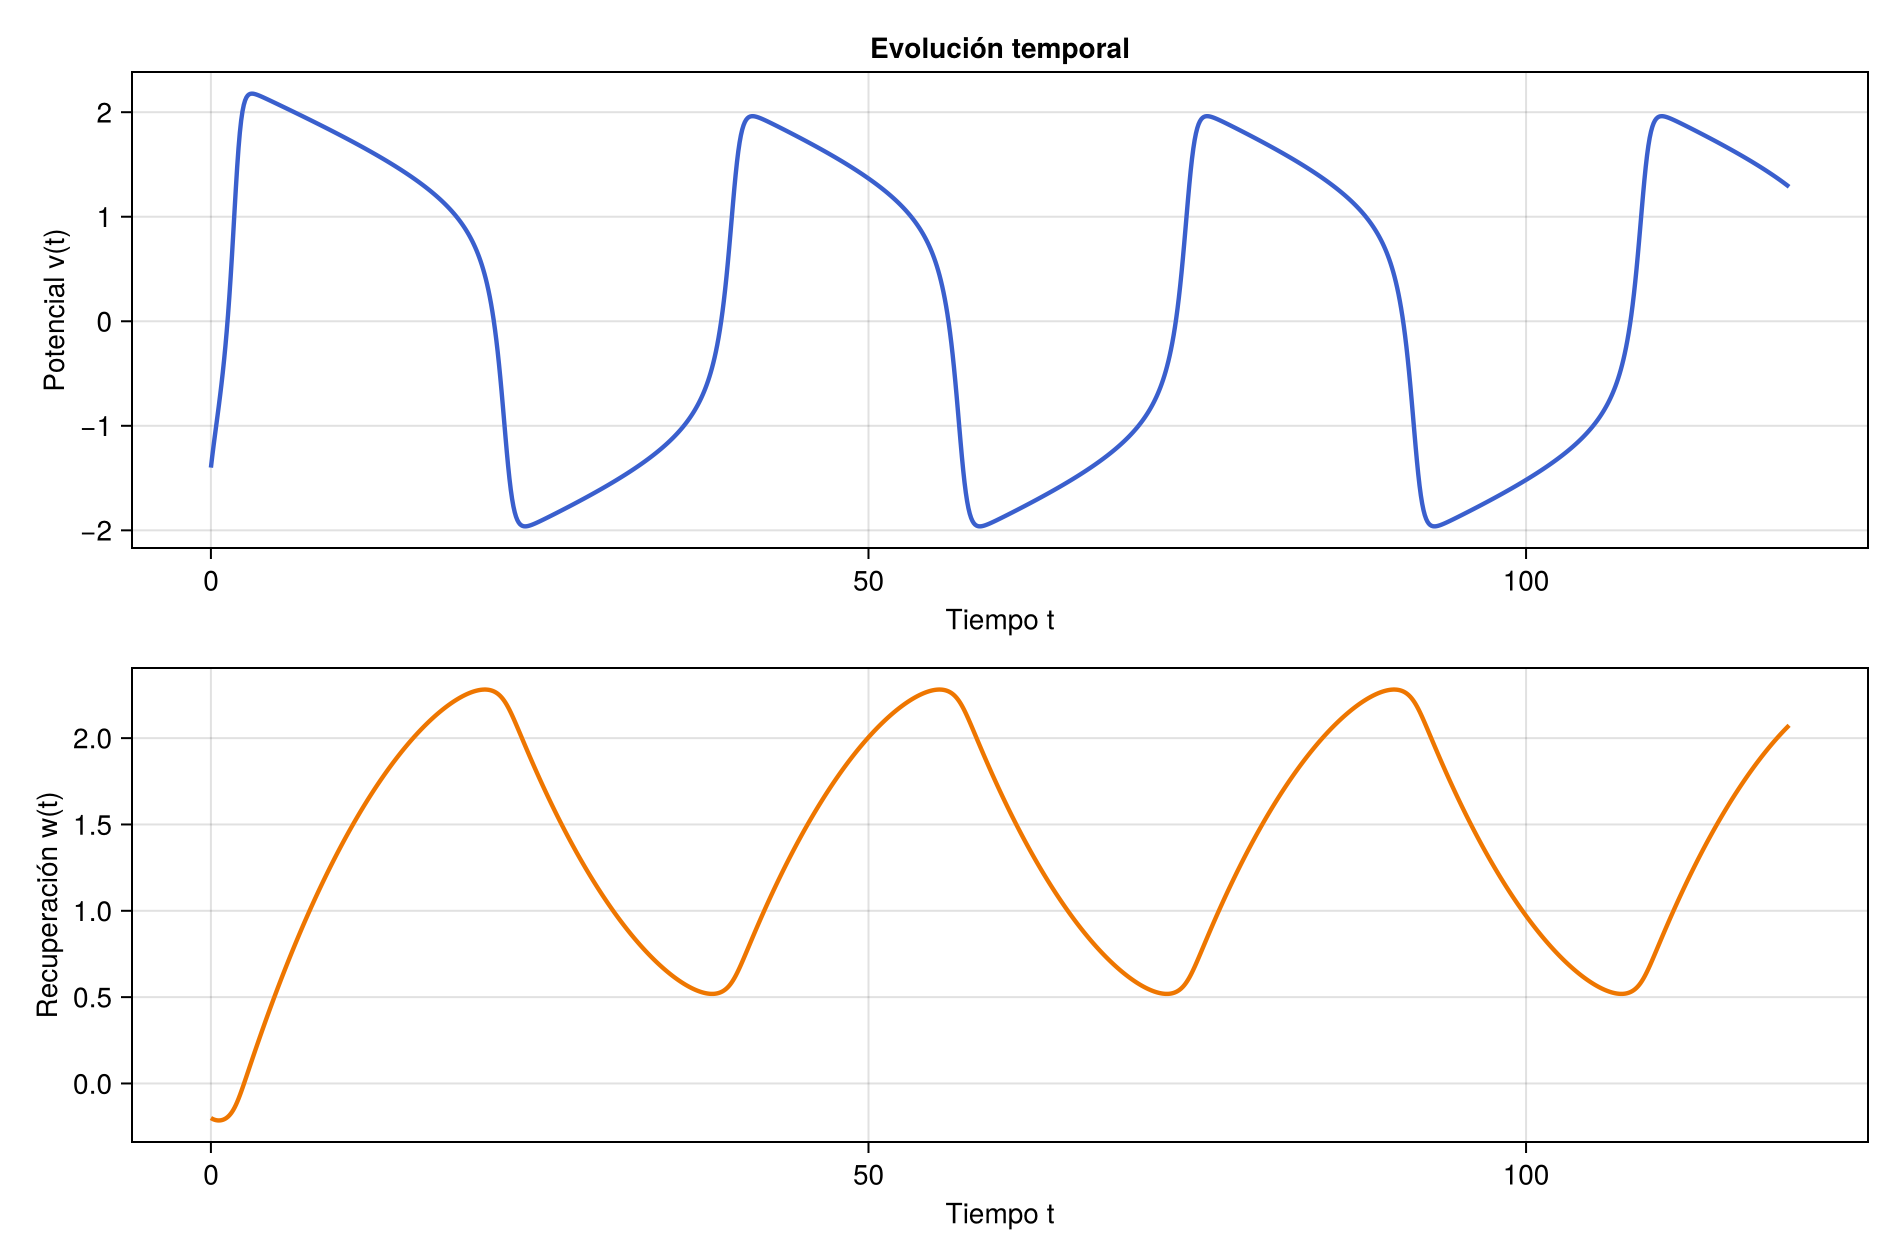

In [4]:
u0 = (-1.4, -0.2)
sol = simulate_individual(p; u0=u0, tspan=(0.0, 120.0),
                          saveat=0.1, reltol=1e-9, abstol=1e-9)
plot_timeseries(sol)

## 3. Retrato de fase con campo de direcciones y nulclinas

- Nulclina de potencial: $w=v-v^3/3+I$.
- Nulclina de recuperación: $w=(v+a)/b$ cuando $b>0$.
- El equilibrio está en la intersección.

Las trayectorias se integran una sola vez y se envían al módulo de gráficos.

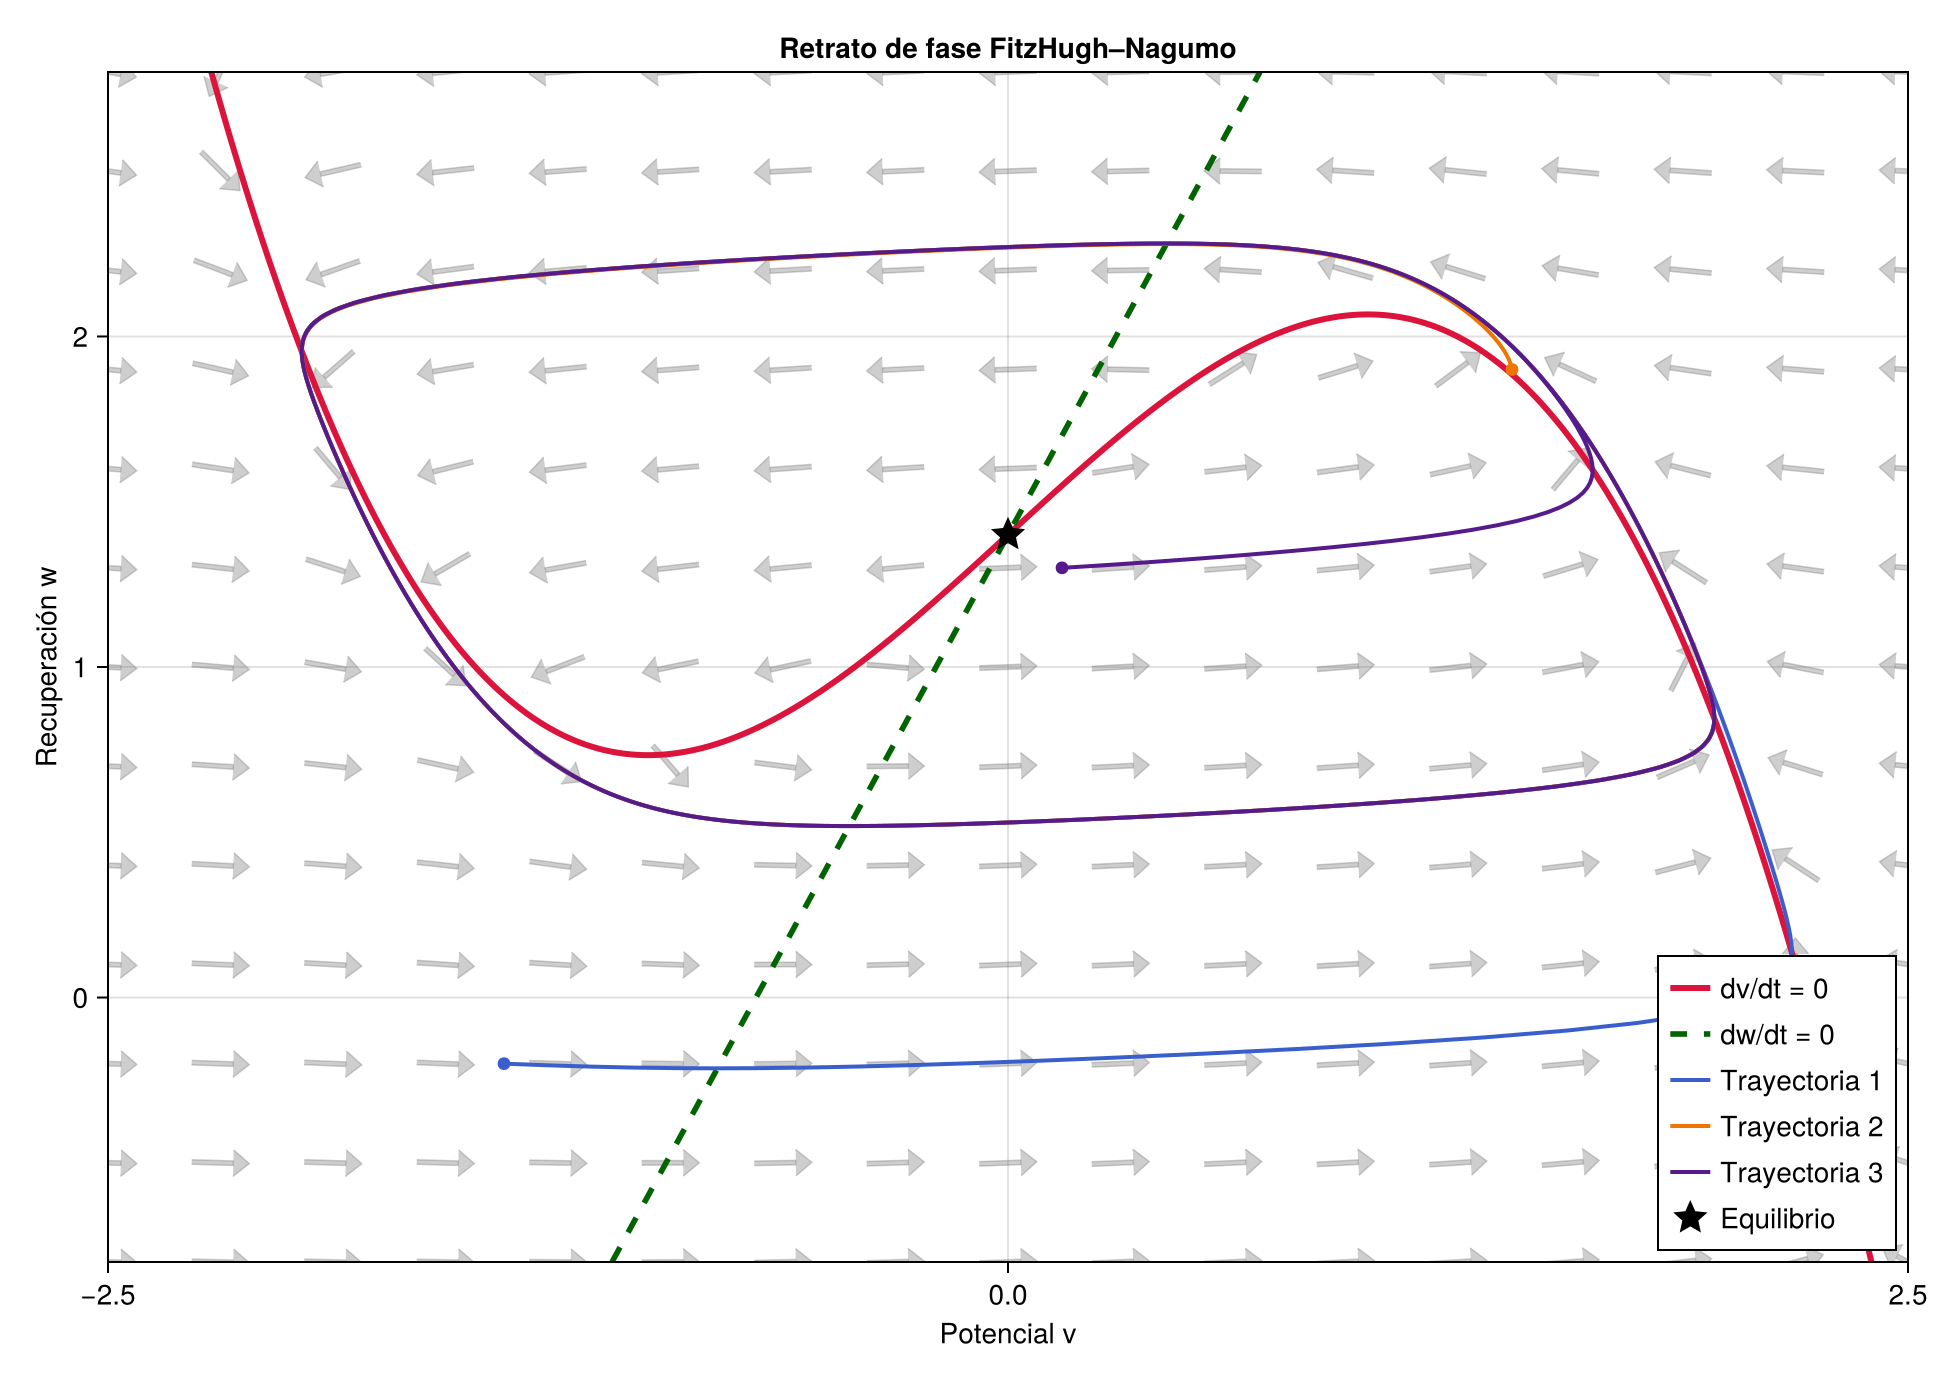

In [5]:
condiciones_iniciales = [(-1.4, -0.2), (1.4, 1.9), (0.15, 1.3)]
soluciones = simulate_ensemble(p, condiciones_iniciales;
                               tspan=(0.0, 120.0), saveat=0.12)
plot_phase_portrait(p, soluciones;
                    vlims=(-2.5, 2.5), wlims=(-0.8, 2.8))

### Trayectorias cerca y lejos del equilibrio

Para un equilibrio inestable, una perturbación pequeña puede crecer. Integramos estados inicialmente cercanos y alejados. **La proximidad del dibujo no prueba por sí sola la existencia de un ciclo límite.**

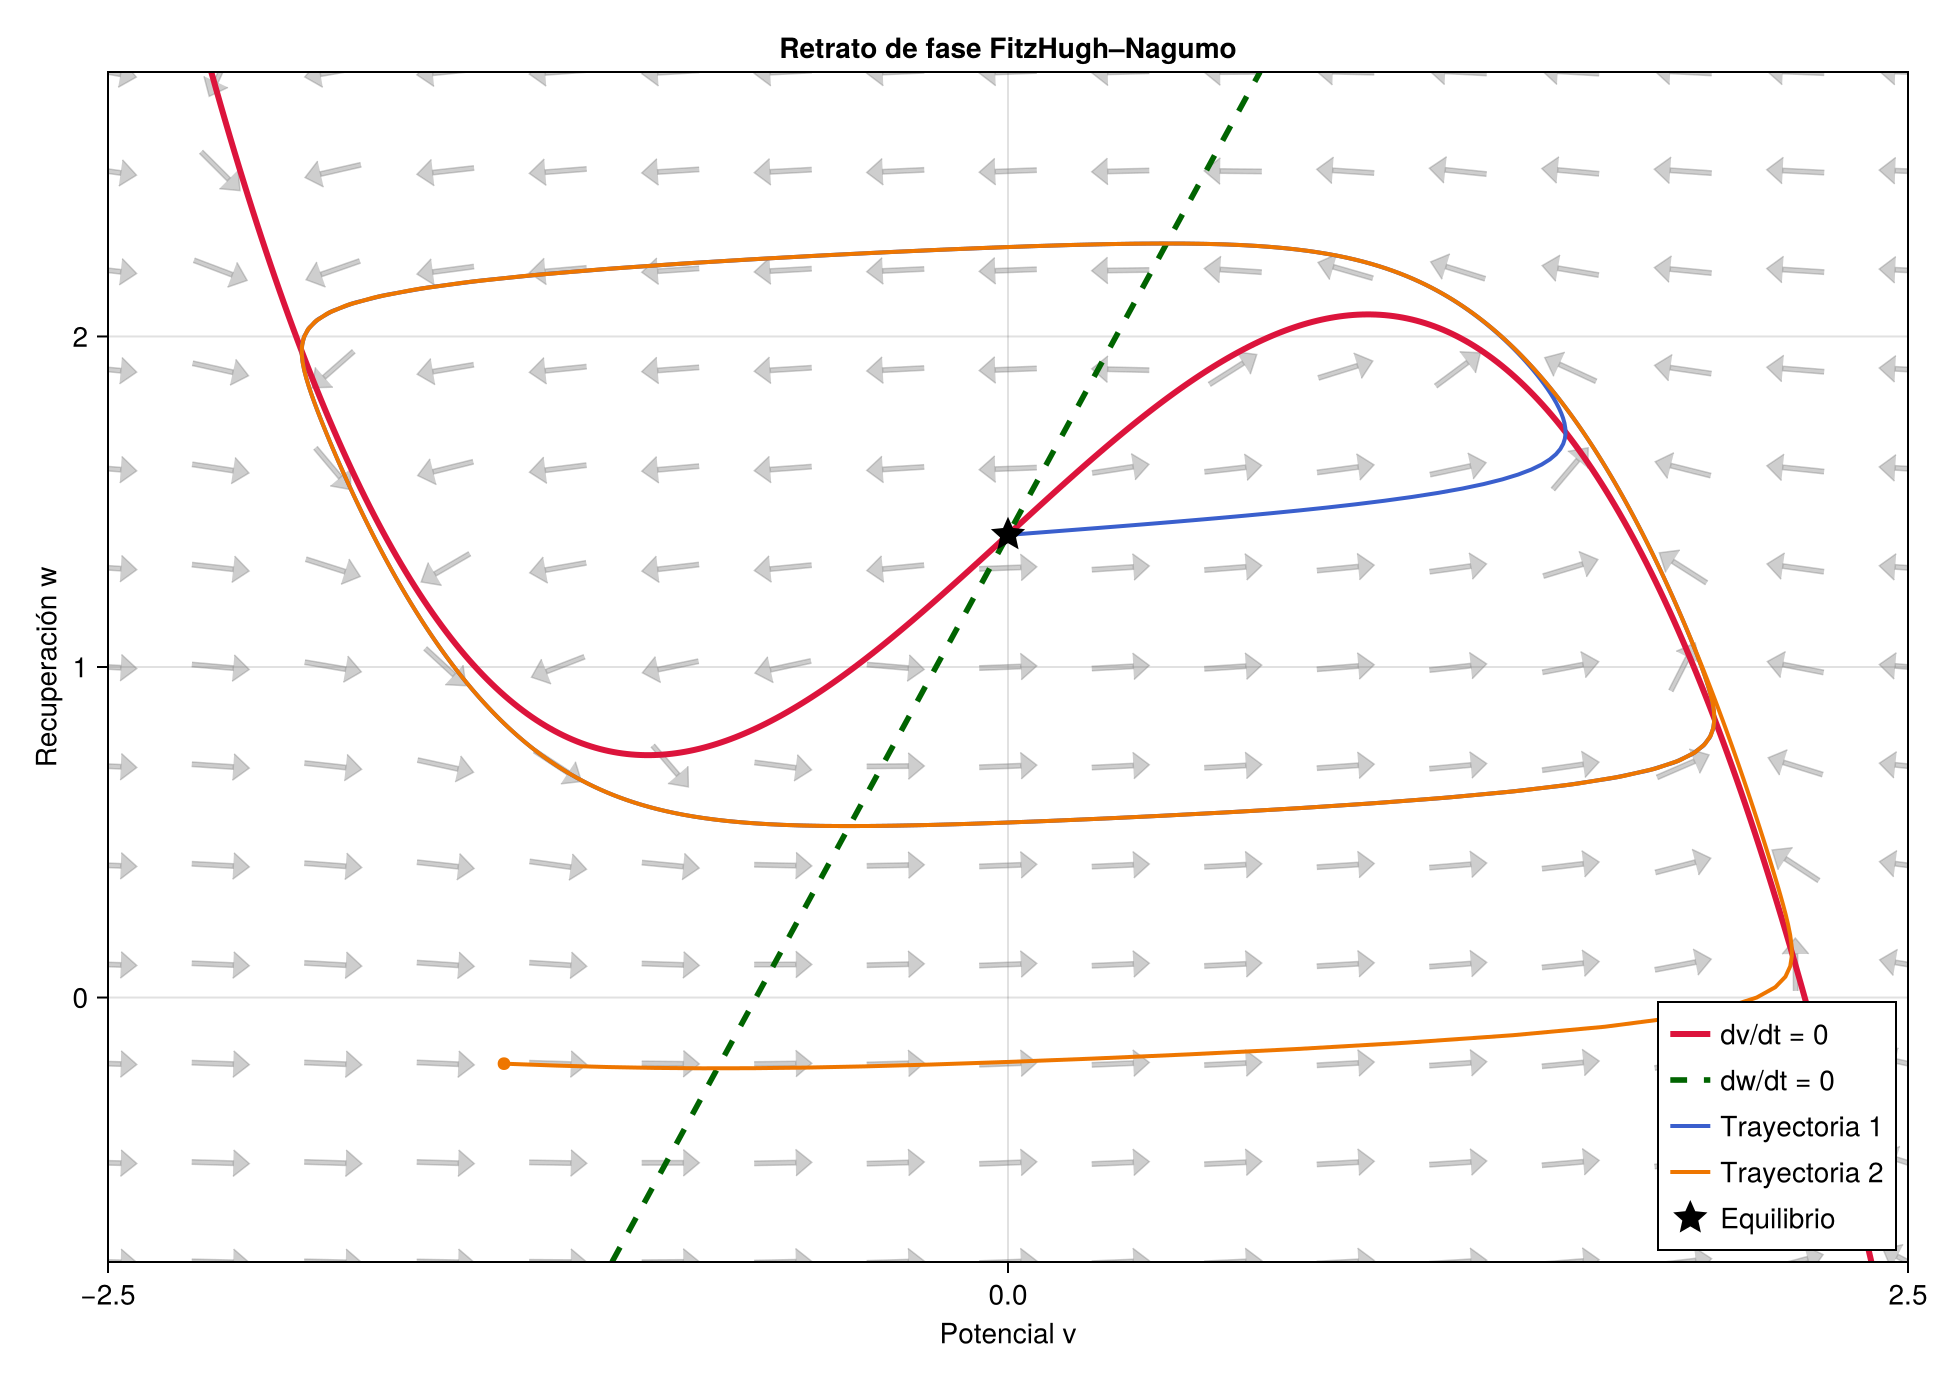

In [6]:
z_cerca = (zstar[1] + 0.005, zstar[2])
z_lejos = (zstar[1] - 1.4, zstar[2] - 1.6)
trayectorias_comparacion = simulate_ensemble(p, [z_cerca, z_lejos];
                                              tspan=(0.0, 140.0), saveat=0.14)
plot_phase_portrait(p, trayectorias_comparacion;
                    vlims=(-2.5, 2.5), wlims=(-0.8, 2.8))

## 4. Cambios de estabilidad al variar la corriente $I$

Para $0<b<1$ y $\tau>b$, el cuaderno obtiene las corrientes candidatas de Hopf usando la condición $\operatorname{tr}J^*=0$. Aquí compararemos esos valores teóricos con el signo de la traza calculado a lo largo de la rama de equilibrios. **La continuación de ciclos límite corresponde a la Etapa B.**

Corriente de Hopf inferior: 0.10666941581048195
Corriente de Hopf superior: 2.6933305841895177
Frecuencia lineal en Hopf: 0.28


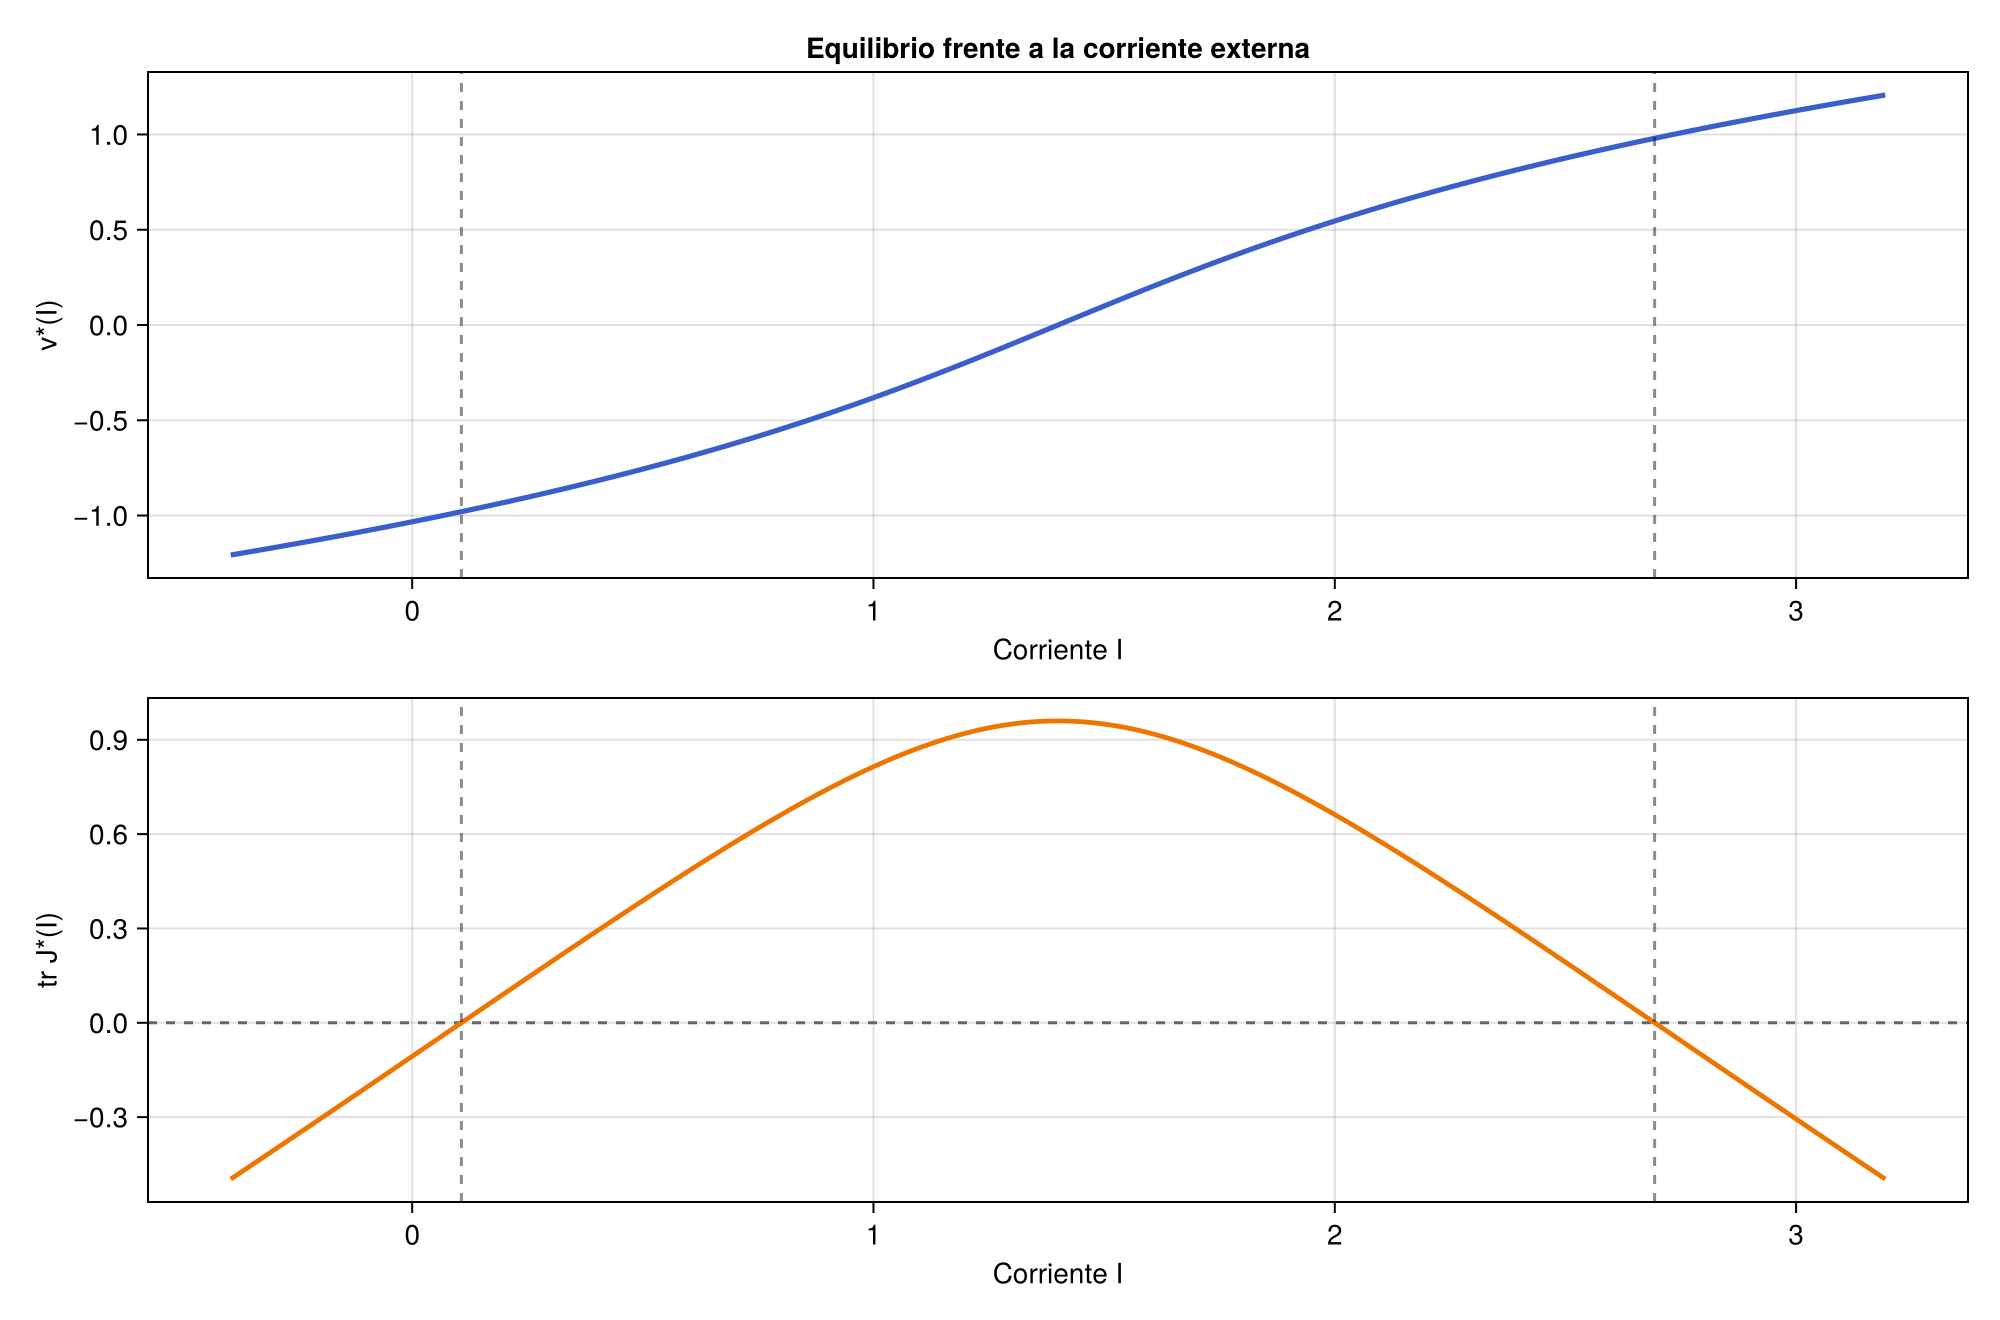

In [7]:
h = hopf_currents(p)
println("Corriente de Hopf inferior: ", h.I_minus)
println("Corriente de Hopf superior: ", h.I_plus)
println("Frecuencia lineal en Hopf: ", h.omega)

sweep = equilibrium_sweep(p, range(h.I_minus - 0.5, h.I_plus + 0.5, length=181))
plot_equilibrium_sweep(p, sweep)

### Tres corrientes representativas

Tomamos una corriente **por debajo** del intervalo crítico, una **dentro** y otra **por encima**. Reportamos primero la estabilidad del equilibrio y después observamos las trayectorias. Estabilidad de un equilibrio no implica por sí sola ausencia de cualquier otra solución recurrente.

I = -0.1933 | v* = -1.1222 | tr J* = -0.2994 | stable
I = 1.4 | v* = 0.0 | tr J* = 0.96 | unstable
I = 2.9933 | v* = 1.1222 | tr J* = -0.2994 | stable


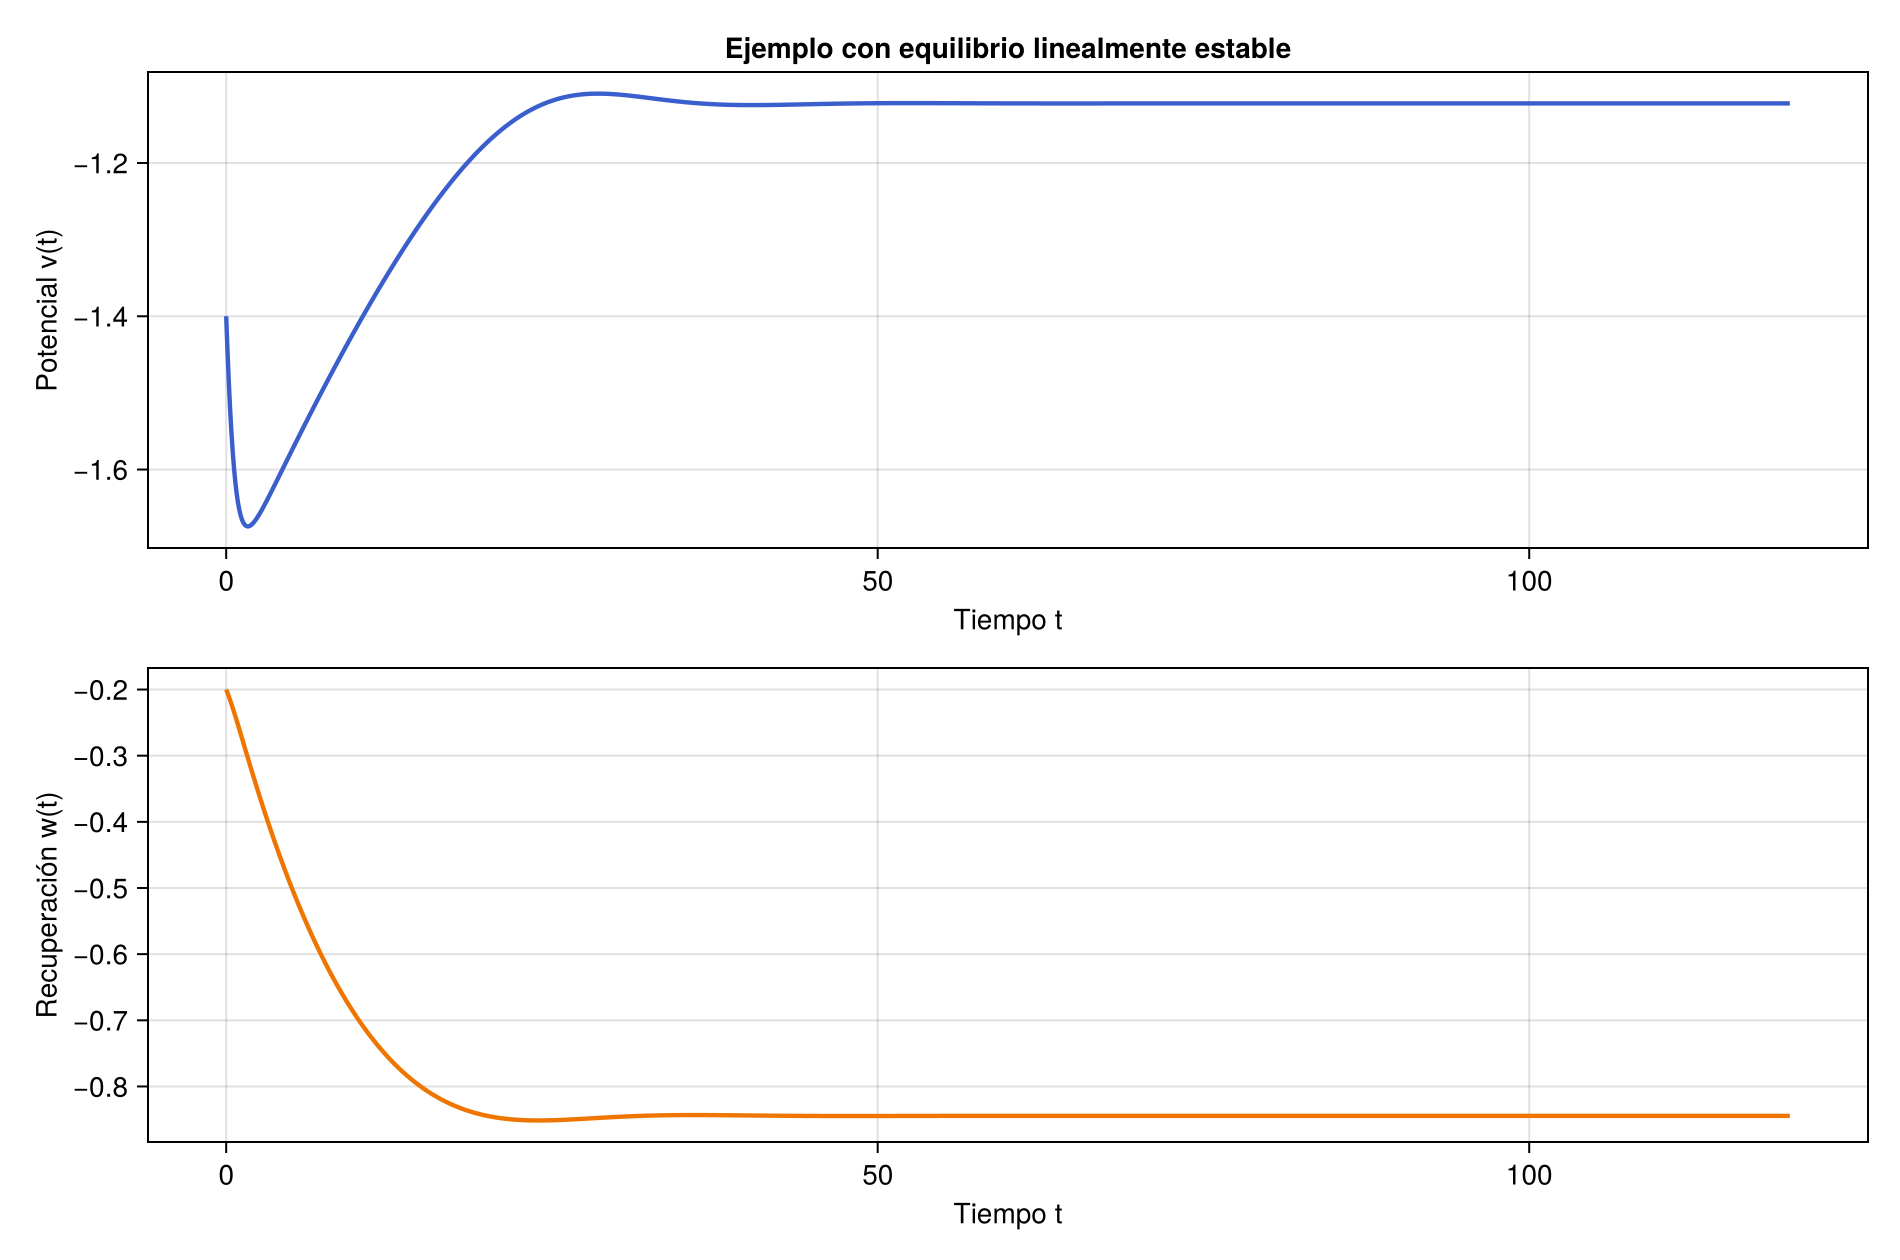

In [8]:
corrientes = [h.I_minus - 0.3, (h.I_minus + h.I_plus) / 2, h.I_plus + 0.3]
for I in corrientes
    q = with_current(p, I)
    s = stability_info(q)
    println("I = ", round(I; digits=4), " | v* = ",
            round(s.equilibrium[1]; digits=4), " | tr J* = ",
            round(s.trace; digits=4), " | ", s.classification)
end

# Comparación gráfica para dos de los regímenes, conservando la misma condición inicial.
q_estable = with_current(p, corrientes[1])
sol_estable = simulate_individual(q_estable; u0=u0, tspan=(0.0, 120.0))
plot_timeseries(sol_estable; title="Ejemplo con equilibrio linealmente estable")

### Sensibilidad al variar $a$, $b$, $\tau$ e $I$

Cada barrido cambia **solo un parámetro** y mantiene los otros tres. Graficamos la traza del jacobiano; es un estudio del equilibrio, no una clasificación global de todas las trayectorias.

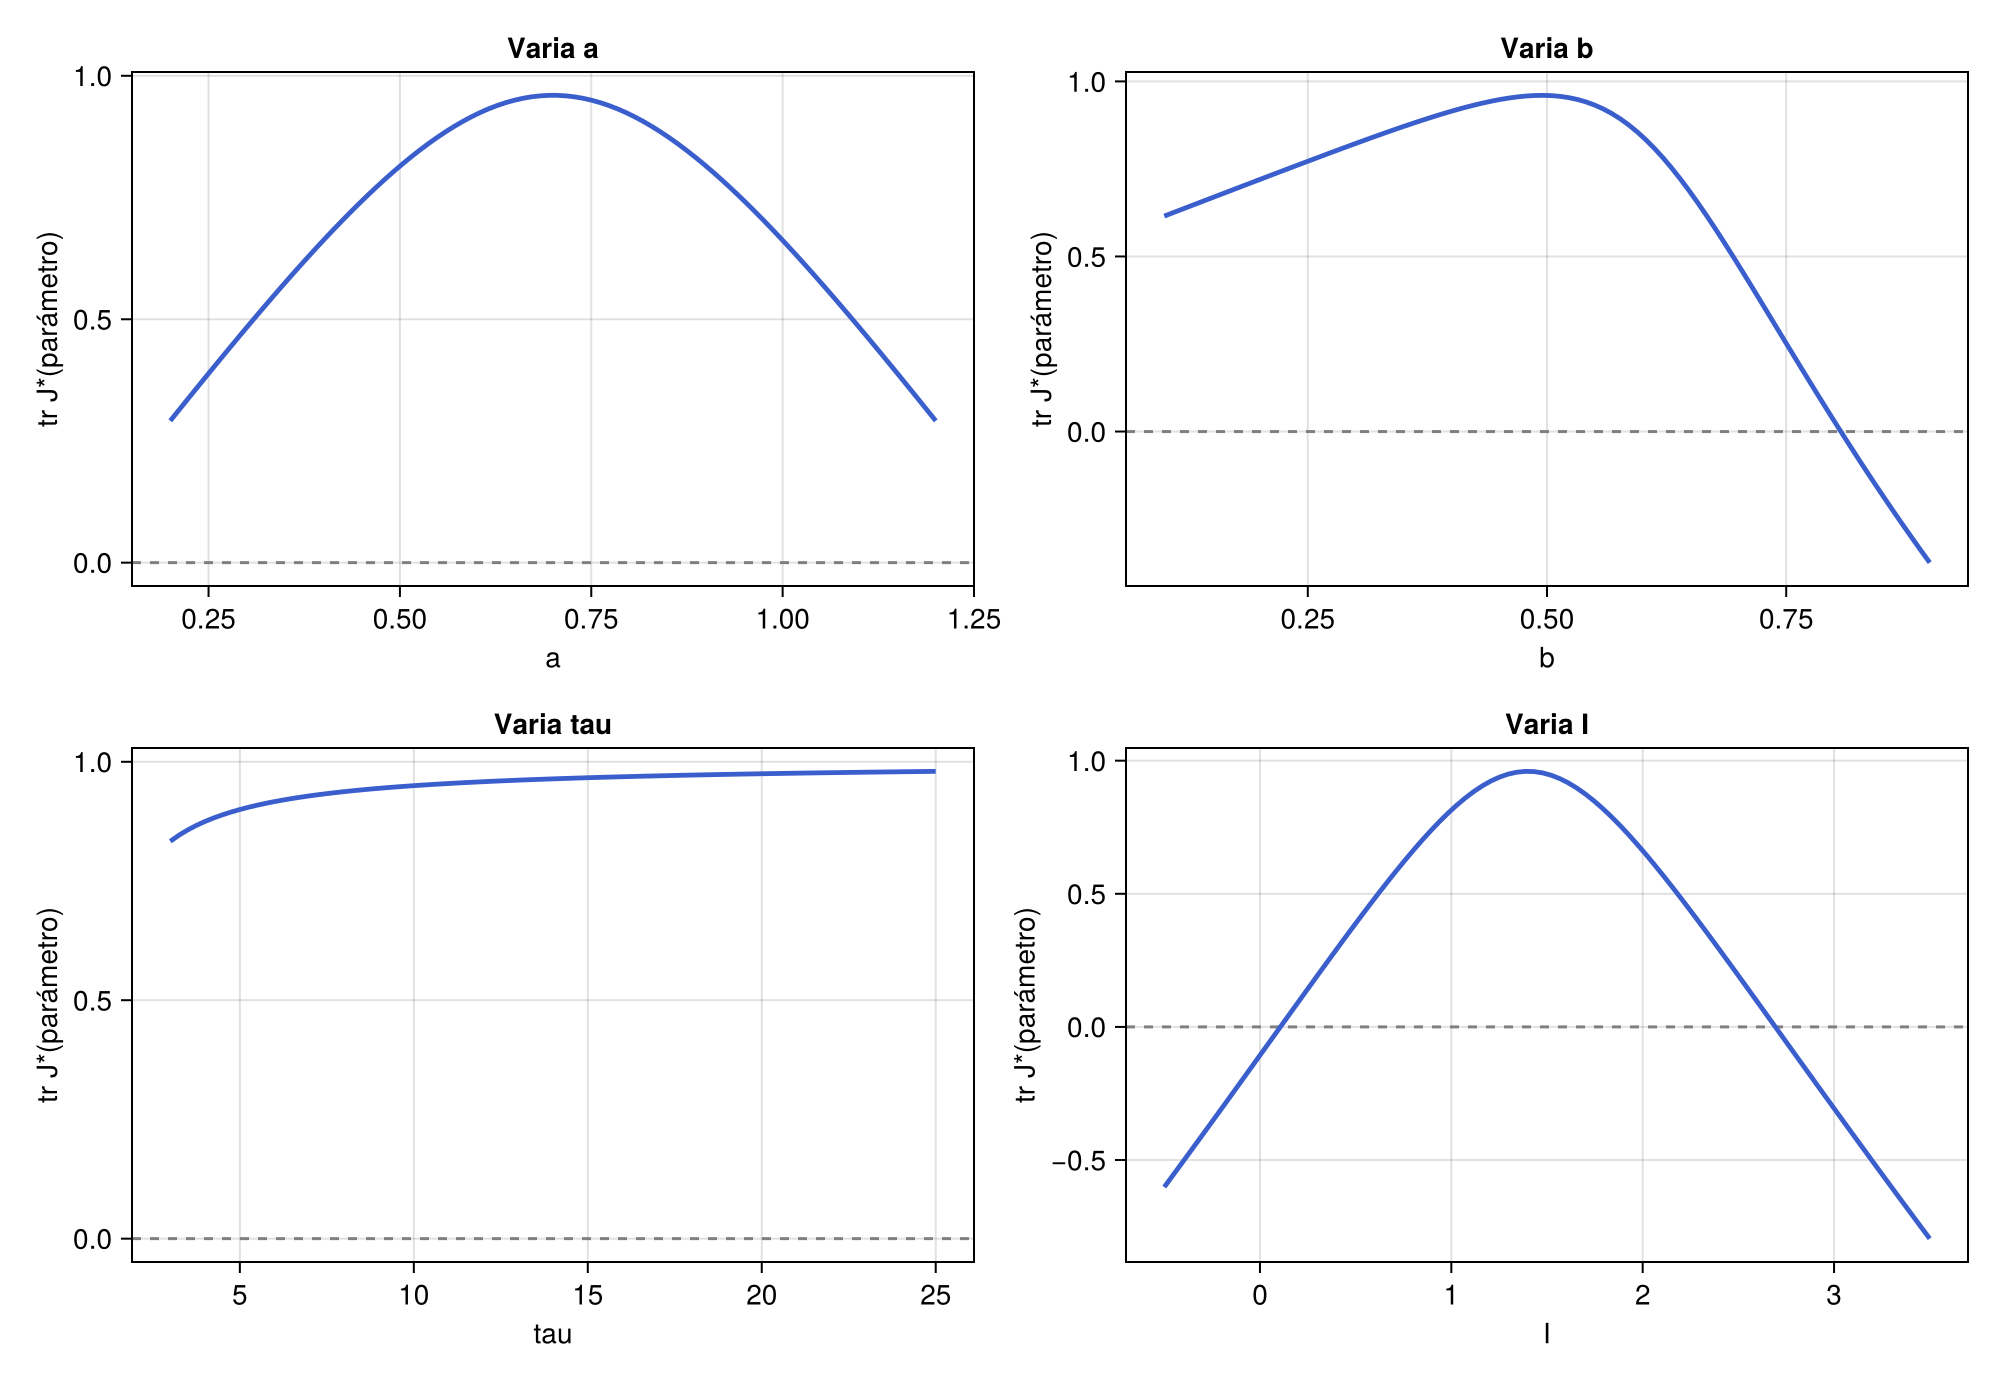

In [9]:
intervalos = [
    (:a, range(0.2, 1.2, length=90)),
    (:b, range(0.1, 0.9, length=90)),
    (:tau, range(3.0, 25.0, length=90)),
    (:I, range(-0.5, 3.5, length=90)),
]

fig_param = Figure(size=(1000, 690))
for (j, (nombre, valores)) in enumerate(intervalos)
    resultado = parameter_sweep(p, nombre, valores)
    fila = div(j - 1, 2) + 1
    columna = mod(j - 1, 2) + 1
    ax = Axis(fig_param[fila, columna], title="Varia " * string(nombre),
              xlabel=string(nombre), ylabel="tr J*(parámetro)")
    hlines!(ax, [0.0]; color=:gray, linestyle=:dash)
    lines!(ax, resultado.values, resultado.trace; color=:royalblue3, linewidth=2.4)
end
fig_param

## 5. Caso especial $b=0$

El enunciado lo admite; en ese caso $v^*=-a$, $w^*=f(-a)+I$. La nulclina de recuperación **es vertical**: $v=-a$. No debemos dividir por cero al graficarla.

Equilibrio con b=0: [-0.7, 0.8143333333333332]
Candidatos clásicos de Hopf al variar I: nothing


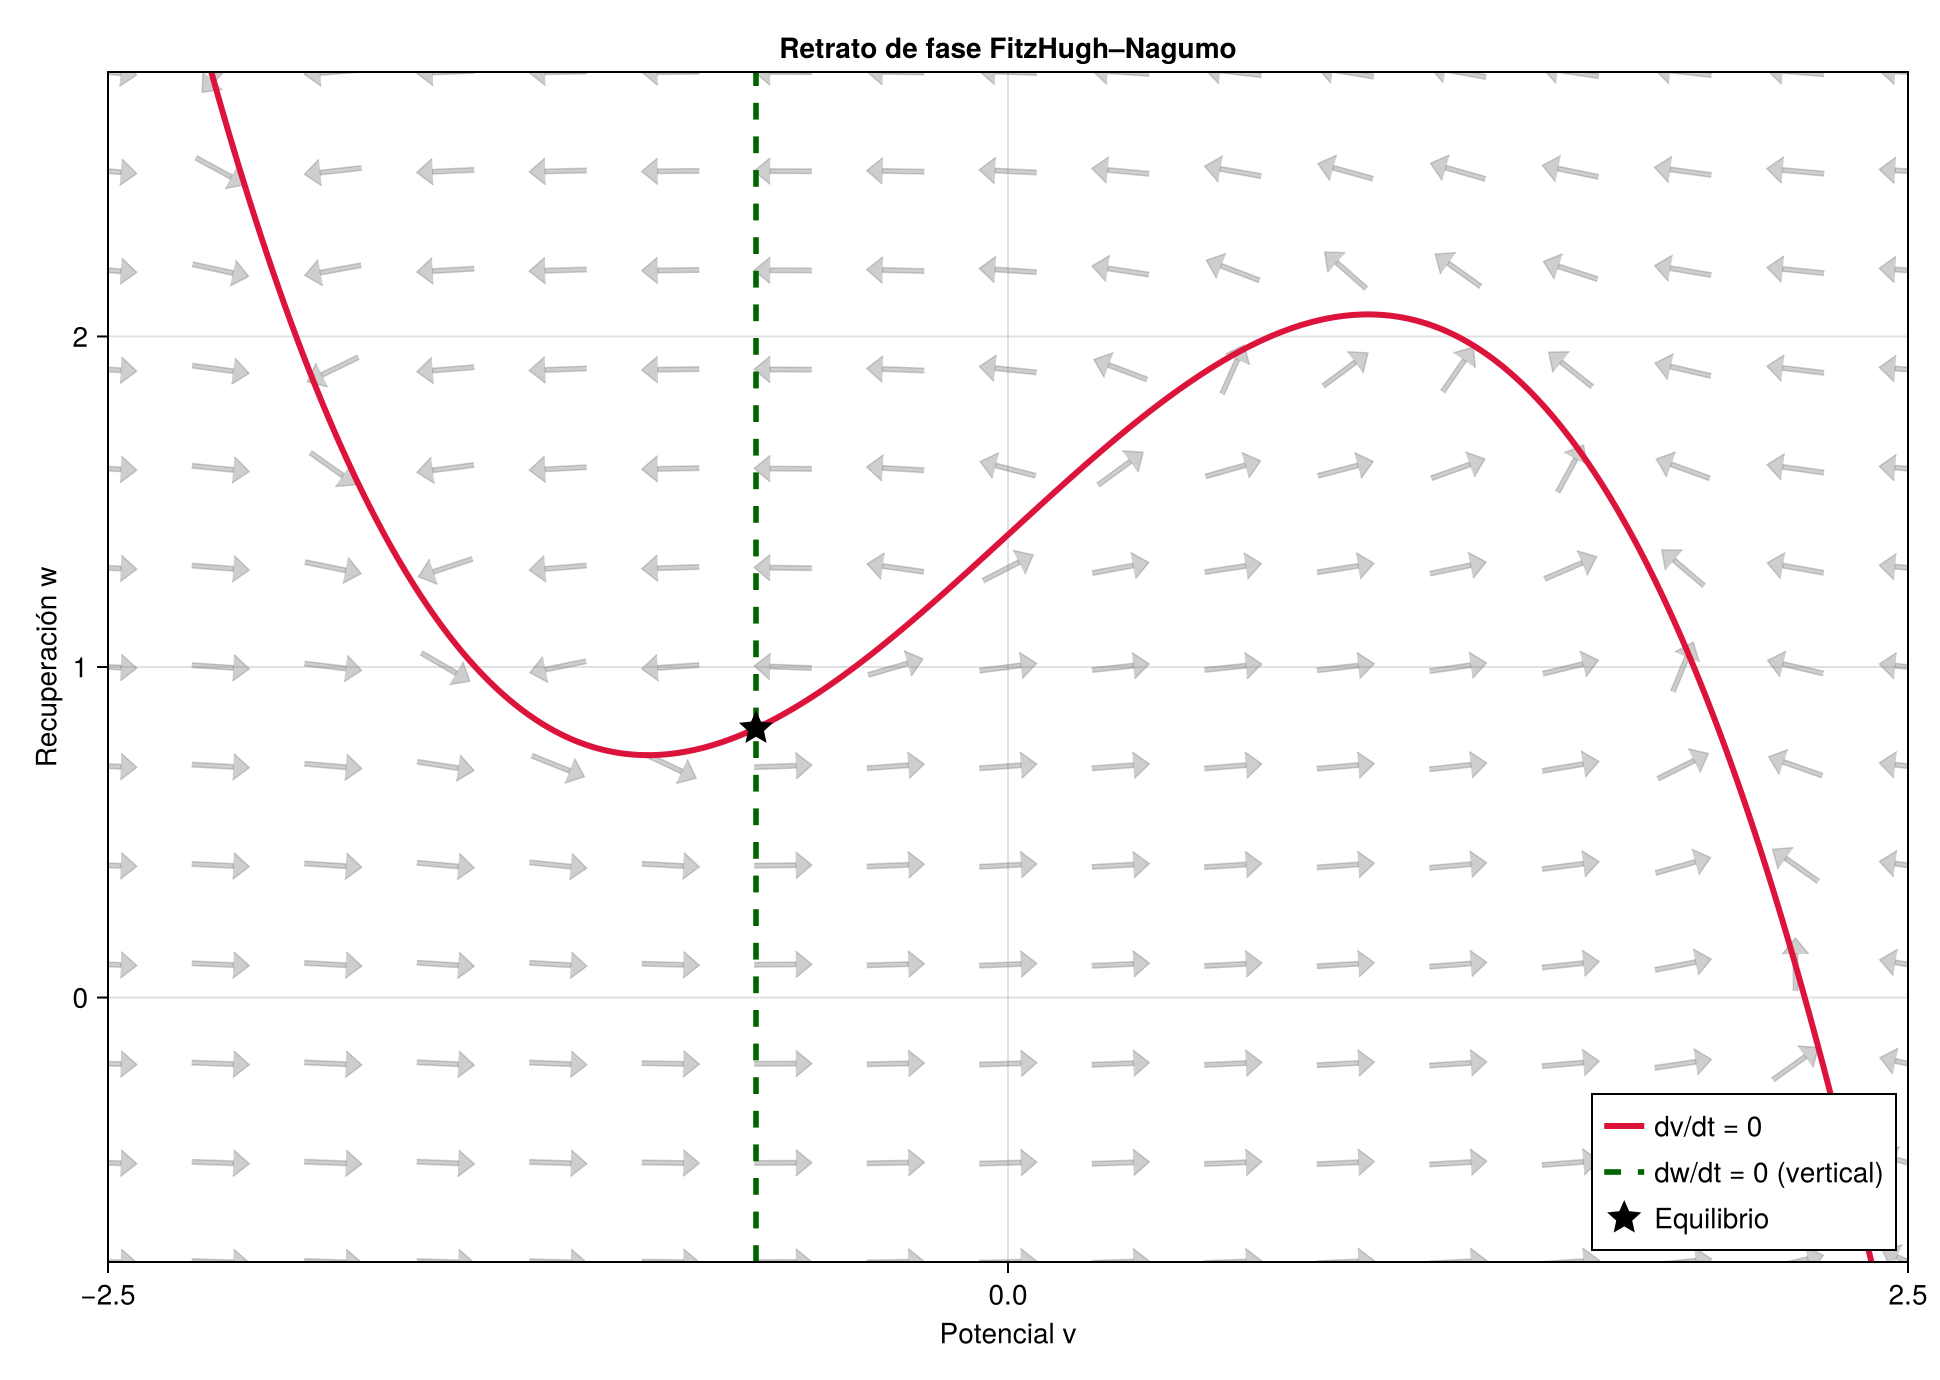

In [10]:
p_b0 = FHNParameters(a=0.7, b=0.0, tau=12.5, I=1.4)
println("Equilibrio con b=0: ", equilibrium(p_b0))
println("Candidatos clásicos de Hopf al variar I: ", hopf_currents(p_b0))
plot_nullclines(p_b0; vlims=(-2.5, 2.5), wlims=(-0.8, 2.8))

## 6. Comprobación de consistencia del integrador

Se compara la misma trayectoria con dos tolerancias. Es una **prueba de consistencia**, no una demostración de convergencia global del método.

In [11]:
s7 = simulate_individual(p; u0=u0, tspan=(0.0, 20.0),
                         reltol=1e-7, abstol=1e-7, saveat=0.2)
s10 = simulate_individual(p; u0=u0, tspan=(0.0, 20.0),
                          reltol=1e-10, abstol=1e-10, saveat=0.2)
error_final = norm(s7.u[end] - s10.u[end])
println("Diferencia entre soluciones en t=20: ", error_final)

Diferencia entre soluciones en t=20: 2.5044564933772665e-8


## 7. Guardar figuras sin repetir simulaciones

Los datos `sol`, `soluciones` y `sweep` ya están en memoria. El módulo de visualización puede exportar directamente a PNG a partir de ellos.

In [12]:
destino = joinpath(ROOT, "docs", "figures", "A_01_series_temporales.png")
plot_timeseries(sol; savepath=destino)
println("Guardado en: ", destino)

Guardado en: k:\Repositorios\Proyecto-COPTI\docs\figures\A_01_series_temporales.png
